# ❓基于异常收益的注意力溢出（SPILL）

**行为金融因子 —— 投资者注意力溢出效应**

首先，计算每月平均异常日收益率作为个股层面的注意力代理指标：

$$
\text{ATTN}_{i,t} = \frac{1}{m} \sum_{t}^{t-m+1} \left( r_{i,t} - \bar{r}_t \right)^2
$$

其中，$r_{i,t}$ 为股票 $i$ 在交易日 $t$ 的收益率，$\bar{r}_t$ 为交易日 $t$ 的全市场收益率，$m$ 为交易日窗口，一般取为月度。进一步，计算当期相近股票的注意力均值与个股注意力之差，即为注意力溢出程度：

$$
\text{SPILL}_{i,t} = \text{ATTN}_{i,t} - \overline{\text{ATTN}}_{g(i),t}
$$

其中，$\overline{\text{ATTN}}_{g(i),t}$ 为股票 $i$ 所属分组 $g(i)$ 内所有股票在 $t$ 期的注意力均值（不含股票 $i$ 自身）。

## 分组标准

相近股票的确定标准如下：

1. 先以中信一级行业作为分类标准，将全市场股票划分为不同行业；
2. 在每个行业内，按市值规模从大到小排序，以 **3:4:3** 的比例将股票分为**大市值、中市值、小市值**三组；
3. 同一行业同一市值组内的股票即被定义为“相近股票”。

## 因子逻辑说明

投资者注意力存在**溢出效应**：当某只股票受到高度关注时，投资者往往会同时注意到与其特征相似（同行业、同市值规模）的“邻居”股票，从而导致这些相近股票也获得一定的关注度提升，并享有注意力溢价。上述因子以异常收益（收益相对于市场的偏离程度）作为注意力的代理指标，通过计算个股注意力与其相近股票平均注意力之间的差值来衡量溢出程度。$\text{SPILL}_{i,t}$ 越大，表明个股当前受到的关注显著高于其同类股票，未来注意力向相近股票溢出的效应越显著，相近股票预期将取得正向超额收益。

数据：中信一级行业、日度市值、日度收盘价

In [1]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_price,
    get_factor,
    get_trading_dates,
    get_instrument_industry,
)

def _spill_get_all_a_ids():
    return (
        all_instruments("CS")["order_book_id"]
        .dropna()
        .drop_duplicates()
        .tolist()
    )

def _spill_get_close_volume(batch, price_dates):
    raw = get_price(
        order_book_ids=batch,
        start_date=price_dates[0],
        end_date=price_dates[-1],
        frequency="1d",
        fields=["close", "volume"],
        adjust_type="pre",
        skip_suspended=False,
        expect_df=True,
    )

    if raw is None or raw.empty:
        return None, None

    if isinstance(raw.index, pd.MultiIndex):
        close = raw["close"].unstack("order_book_id")
        volume = raw["volume"].unstack("order_book_id")
    else:
        close = raw[["close"]].rename(columns={"close": batch[0]})
        volume = raw[["volume"]].rename(columns={"volume": batch[0]})

    close.index = pd.to_datetime(close.index)
    volume.index = pd.to_datetime(volume.index)

    return (
        close.reindex(index=price_dates, columns=batch),
        volume.reindex(index=price_dates, columns=batch),
    )


def _spill_get_market_cap_wide(order_book_ids, dates, batch_size=500):
    """下载市值因子，整理为 日期 × 股票 宽表。"""
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_factor(
            order_book_ids=batch,
            factor="market_cap_3",
            start_date=dates[0],
            end_date=dates[-1],
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            market_cap = raw["market_cap_3"].unstack("order_book_id")
        else:
            market_cap = raw[["market_cap_3"]].rename(
                columns={"market_cap_3": batch[0]}
            )

        market_cap.index = pd.to_datetime(market_cap.index)
        parts.append(
            market_cap.reindex(index=dates, columns=batch)
        )

    if not parts:
        raise RuntimeError("未取得 market_cap_3 市值数据。")

    market_cap_wide = pd.concat(parts, axis=1)
    market_cap_wide = market_cap_wide.loc[
        :, ~market_cap_wide.columns.duplicated()
    ]

    return market_cap_wide.reindex(
        index=dates,
        columns=order_book_ids,
    )


def _spill_get_industry_codes(
    order_book_ids,
    asof_date,
    industry_source="citics_2019",
    industry_level=1,
    batch_size=500,
):
    """获取指定时点的行业代码。"""
    field_map = {
        1: "first_industry_code",
        2: "second_industry_code",
        3: "third_industry_code",
    }
    industry_field = field_map[industry_level]

    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_instrument_industry(
            order_book_ids=batch,
            source=industry_source,
            level=industry_level,
            date=asof_date,
        )

        if raw is not None and not raw.empty:
            parts.append(raw[industry_field])

    if not parts:
        return pd.Series(index=order_book_ids, dtype=object)

    industry_code = pd.concat(parts)
    industry_code = industry_code[
        ~industry_code.index.duplicated(keep="last")
    ]

    return industry_code.reindex(order_book_ids)


def calculate_spill_daily(
    start_date,
    end_date,
    attention_window=20,
    candidate_ids=None,
    market_ids=None,
    peer_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    min_market_stocks=500,
    min_group_stocks=2,
    batch_size=500,
):
    """
    基于异常收益的注意力溢出（SPILL）

    输出：
        MultiIndex DataFrame
        index  : [date, order_book_id]
        column : SPILL

    参数：
        candidate_ids：输出因子值的股票池；None 为全 A 股。
        market_ids：计算市场平均收益的股票池；None 为全 A 股。
        peer_ids：计算行业-市值组均值的股票池；None 为全 A 股。
        industry_refresh：行业归属更新频率，支持 "M"、"Q"、"D"。
    """
    if attention_window < 1:
        raise ValueError("attention_window 必须为正整数。")

    if industry_level not in (1, 2, 3):
        raise ValueError("industry_level 仅支持 1、2、3。")

    if industry_refresh not in ("M", "Q", "D"):
        raise ValueError("industry_refresh 仅支持 'M'、'Q'、'D'。")

    # 仅在需要时下载全 A 股名单
    all_a_ids = None
    if (
        candidate_ids is None
        or market_ids is None
        or peer_ids is None
    ):
        all_a_ids = _spill_get_all_a_ids()

    candidate_ids = (
        all_a_ids
        if candidate_ids is None
        else list(dict.fromkeys(candidate_ids))
    )
    market_ids = (
        all_a_ids
        if market_ids is None
        else list(dict.fromkeys(market_ids))
    )
    peer_ids = (
        all_a_ids
        if peer_ids is None
        else list(dict.fromkeys(peer_ids))
    )

    # 目标股票也必须进入同组均值的计算范围
    peer_ids = list(dict.fromkeys(peer_ids + candidate_ids))
    price_ids = list(
        dict.fromkeys(candidate_ids + market_ids + peer_ids)
    )

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max((attention_window + 1) * 3, 90)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < attention_window:
        raise ValueError("历史交易日不足，无法计算异常收益滚动均值。")

    # 额外取一天价格，以获得第一个历史收益率
    price_dates = calendar[first_loc - attention_window:last_loc + 1]

    # 1. 下载价格，构造全市场日收益率
    return_parts = []
    market_return_sum = pd.Series(0.0, index=price_dates[1:])
    market_return_count = pd.Series(0, index=price_dates[1:])

    for start in range(0, len(price_ids), batch_size):
        batch = price_ids[start:start + batch_size]

        close, volume = _spill_get_close_volume(
            batch=batch,
            price_dates=price_dates,
        )

        if close is None:
            continue

        stock_return = close.pct_change(fill_method=None).iloc[1:]

        # 停牌日不使用“价格不变”的伪收益率
        stock_return = stock_return.where(volume.iloc[1:].gt(0))
        return_parts.append(stock_return)

        market_part = stock_return.reindex(columns=market_ids)
        market_return_sum = market_return_sum.add(
            market_part.sum(axis=1, skipna=True),
            fill_value=0.0,
        )
        market_return_count = market_return_count.add(
            market_part.notna().sum(axis=1),
            fill_value=0,
        )

    if not return_parts:
        raise RuntimeError("未取得有效价格数据。")

    returns_wide = pd.concat(return_parts, axis=1)
    returns_wide = returns_wide.loc[
        :, ~returns_wide.columns.duplicated()
    ]
    returns_wide = returns_wide.reindex(
        index=price_dates[1:],
        columns=price_ids,
    )

    market_return = (
        market_return_sum / market_return_count.replace(0, np.nan)
    ).where(market_return_count >= min_market_stocks)

    # 2. ATTN：过去 attention_window 日平均平方异常收益
    attention_wide = (
        returns_wide.sub(market_return, axis=0)
        .pow(2)
        .rolling(
            window=attention_window,
            min_periods=attention_window,
        )
        .mean()
        .reindex(target_dates)
    )

    # 3. 获取每日市值；行业归属按月初更新
    market_cap_wide = _spill_get_market_cap_wide(
        order_book_ids=peer_ids,
        dates=target_dates,
        batch_size=batch_size,
    )

    industry_wide = pd.DataFrame(
        index=target_dates,
        columns=peer_ids,
        dtype=object,
    )

    if industry_refresh == "D":
        refresh_mask = np.ones(len(target_dates), dtype=bool)
    else:
        periods = target_dates.to_period(industry_refresh)
        refresh_mask = ~periods.duplicated()

    refresh_locs = np.flatnonzero(refresh_mask)

    for pos, begin_loc in enumerate(refresh_locs):
        end_loc = (
            refresh_locs[pos + 1]
            if pos + 1 < len(refresh_locs)
            else len(target_dates)
        )
        block_dates = target_dates[begin_loc:end_loc]

        industry_code = _spill_get_industry_codes(
            order_book_ids=peer_ids,
            asof_date=block_dates[0],
            industry_source=industry_source,
            industry_level=industry_level,
            batch_size=batch_size,
        )

        industry_wide.loc[block_dates, peer_ids] = np.tile(
            industry_code.values,
            (len(block_dates), 1),
        )

    # 4. 每日行业内按市值 3:4:3 分组，计算剔除自身后的同组均值
    factor_wide = pd.DataFrame(
        index=target_dates,
        columns=candidate_ids,
        dtype=float,
    )

    for date in target_dates:
        day = pd.DataFrame({
            "attention": attention_wide.loc[date, peer_ids],
            "market_cap": market_cap_wide.loc[date, peer_ids],
            "industry": industry_wide.loc[date, peer_ids],
        })

        day = day.dropna(subset=["attention", "market_cap", "industry"])
        day = day[day["market_cap"] > 0]

        if day.empty:
            continue

        # 行业内按市值从大到小排序，并按 3:4:3 分为大、中、小市值组
        day["rank"] = day.groupby("industry")["market_cap"].rank(
            method="first",
            ascending=False,
        )
        day["industry_count"] = day.groupby("industry")[
            "market_cap"
        ].transform("count")

        large_cutoff = np.ceil(day["industry_count"] * 0.3)
        middle_cutoff = np.ceil(day["industry_count"] * 0.7)

        day["size_group"] = np.where(
            day["rank"] <= large_cutoff,
            "L",
            np.where(day["rank"] <= middle_cutoff, "M", "S"),
        )

        day["group_key"] = (
            day["industry"].astype(str)
            + "_"
            + day["size_group"]
        )

        group_sum = day.groupby("group_key")["attention"].transform("sum")
        group_count = day.groupby("group_key")["attention"].transform("count")

        # 剔除自身后的同组注意力均值
        peer_attention_mean = (
            (group_sum - day["attention"])
            / (group_count - 1).replace(0, np.nan)
        )

        day["SPILL"] = (
            day["attention"] - peer_attention_mean
        ).where(group_count >= min_group_stocks)

        output = day.loc[
            day.index.isin(candidate_ids),
            "SPILL",
        ]
        factor_wide.loc[date, output.index] = output

    result = factor_wide.stack(dropna=True).rename("SPILL").to_frame()
    result.index = result.index.set_names(["date", "order_book_id"])

    return result

In [2]:
spill = calculate_spill_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    attention_window=20,
    candidate_ids=None,
    market_ids=None,
    peer_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    min_market_stocks=500,
    min_group_stocks=2,
    batch_size=500,
)

spill.head()

SPILL
date       order_book_id          
2020-01-02 000001.XSHE    0.000046
           000002.XSHE   -0.000057
           000004.XSHE    0.000434
           000005.XSHE   -0.000094
           000006.XSHE   -0.000307

In [3]:
spill_df = (
    spill["SPILL"]
    .unstack("order_book_id")
    .sort_index()
)

spill_df.index = pd.to_datetime(spill_df.index)
spill_df.columns.name = "order_book_id"

from rqfactor.notebook import factor_analysis

result_spill = factor_analysis(
    f=spill_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_spill.show()

Loading BokehJS ...

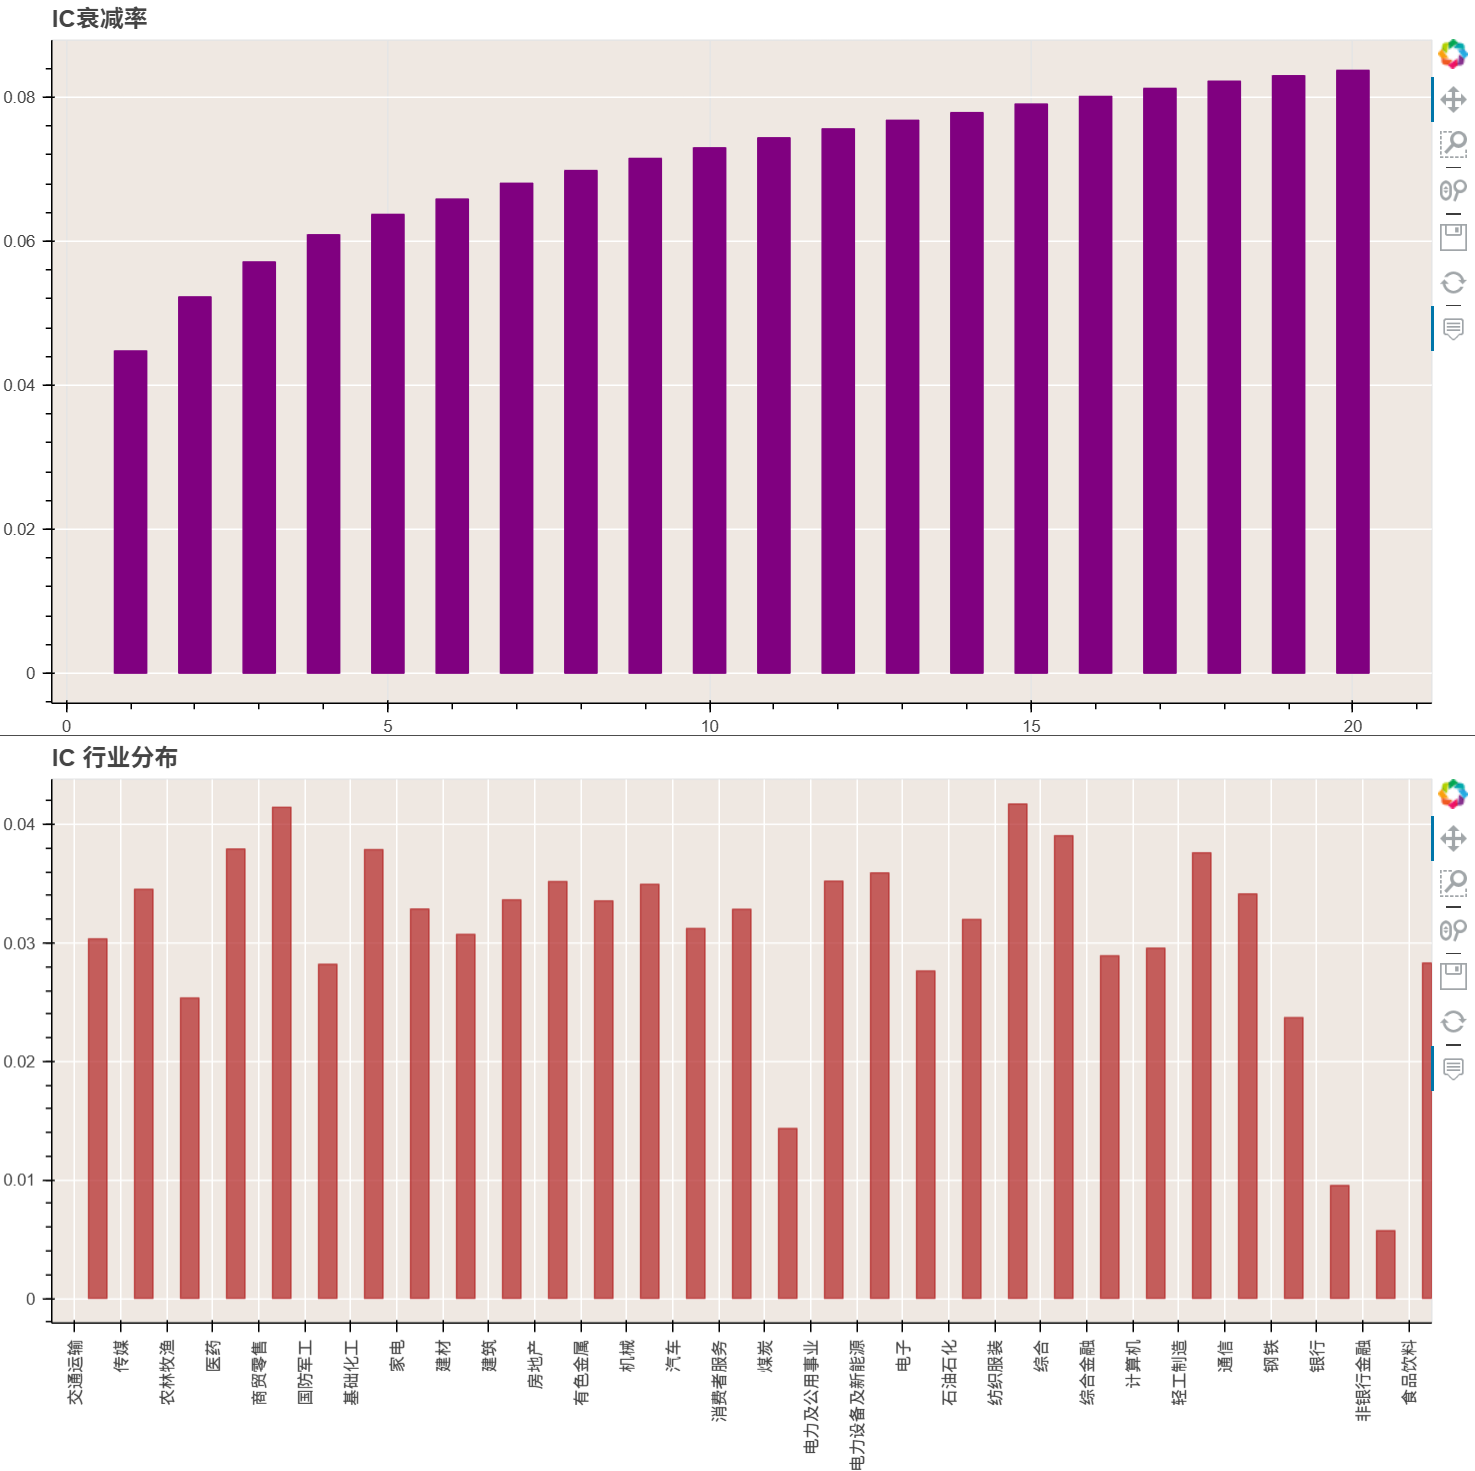

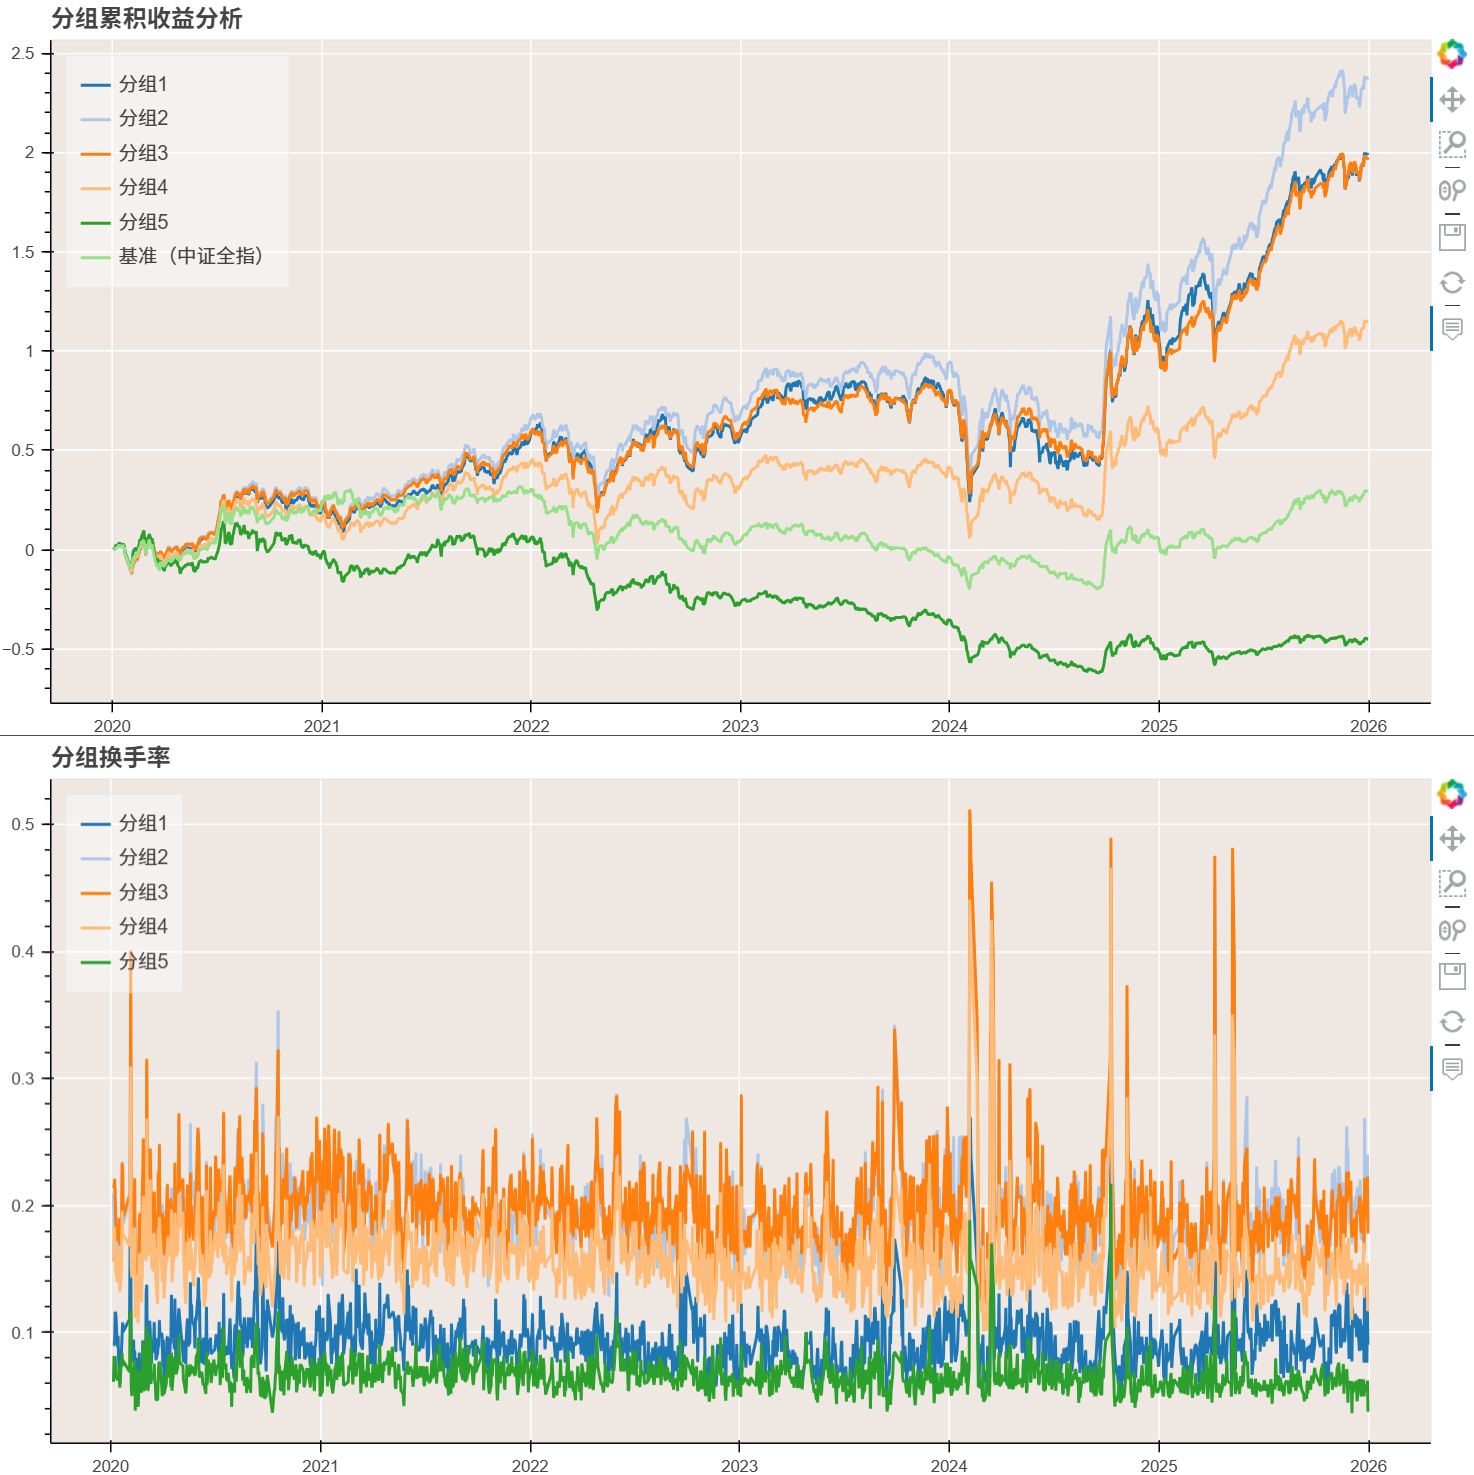

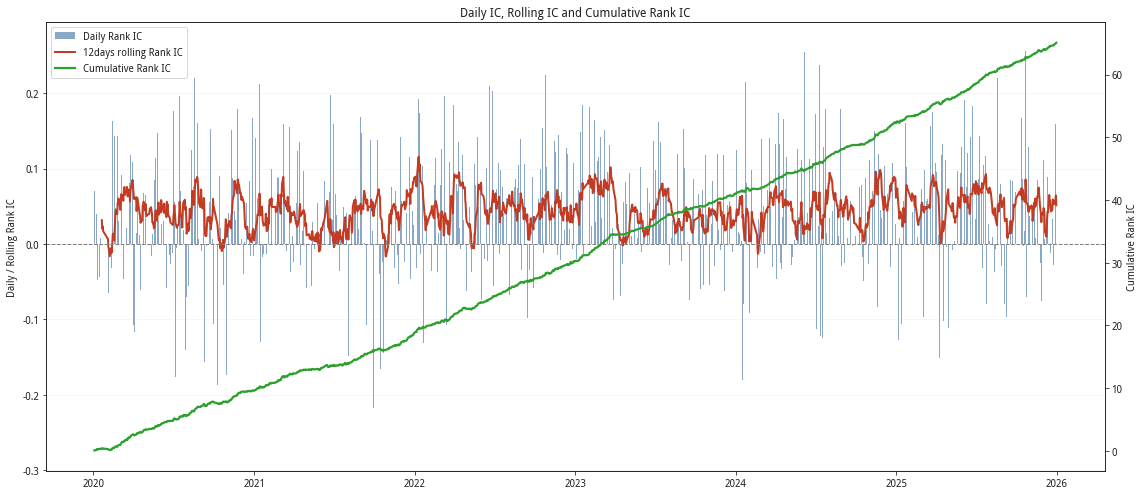

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_spill.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()

# 基于换手率的注意力溢出（SPILL）

**行为金融因子 —— 投资者注意力溢出效应**

首先，计算每月日度换手率均值作为个股层面的注意力代理指标：

$$
\text{ATTN}_{i,t} = \frac{1}{m} \sum_{t=1}^{t-m+1} \text{TURN}_{i,t}
$$

其中，$\text{TURN}_{i,t}$ 为股票 $i$ 在交易日 $t$ 的换手率，$m$ 为交易日窗口，一般取为月度。

进一步，计算当期相近股票的注意力均值与个股注意力之差，即为注意力溢出程度：

$$
\text{SPILL}_{i,t} = \text{ATTN}_{i,t} - \overline{\text{ATTN}}_{g(i),t}
$$

其中，$\overline{\text{ATTN}}_{g(i),t}$ 为股票 $i$ 所属分组 $g(i)$ 内所有股票在 $t$ 期的注意力均值（不含股票 $i$ 自身）。

## 分组标准

相近股票的确定标准如下：

1. 先以**中信一级行业**作为分类标准，将全市场股票划分为不同行业；
2. 在每个行业内，按市值规模从大到小排序，以 **3:4:3** 的比例将股票分为**大市值、中市值、小市值**三组；
3. 同一行业同一市值组内的股票即被定义为“相近股票”。

## 因子说明

投资者注意力存在溢出效应，当一只股票关注度较高时，投资者也会注意到与其相似的邻居股票，导致这些邻居股票的未来收益也会有不错的收益，享有注意力溢价；上述因子以日均换手率为注意力代理指标，计算注意力差值，注意力差值越大，表明未来注意力溢出效应越显著，股票预期会取得正向超额。

In [5]:
import numpy as np
import pandas as pd

from rqdatac import (
    all_instruments,
    get_factor,
    get_instrument_industry,
    get_trading_dates,
    get_turnover_rate,
)


def _turn_spill_get_ids(stock_ids):
    if stock_ids is None:
        return (
            all_instruments("CS")["order_book_id"]
            .dropna()
            .drop_duplicates()
            .tolist()
        )

    if isinstance(stock_ids, str):
        return [stock_ids]

    return list(dict.fromkeys(stock_ids))


def _turn_spill_get_turnover_wide(
    order_book_ids,
    dates,
    batch_size=500,
):
    """下载日换手率，整理为 日期 × 股票 宽表。"""
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_turnover_rate(
            order_book_ids=batch,
            start_date=dates[0],
            end_date=dates[-1],
            fields="today",
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            turnover = raw["today"].unstack("order_book_id")
        else:
            turnover = raw[["today"]].rename(
                columns={"today": batch[0]}
            )

        turnover.index = pd.to_datetime(turnover.index)

        parts.append(
            turnover.reindex(index=dates, columns=batch)
        )

    if not parts:
        raise RuntimeError("未取得有效换手率数据。")

    turnover_wide = pd.concat(parts, axis=1)
    turnover_wide = turnover_wide.loc[
        :, ~turnover_wide.columns.duplicated()
    ]

    return turnover_wide.reindex(
        index=dates,
        columns=order_book_ids,
    )


def _turn_spill_get_market_cap_wide(
    order_book_ids,
    dates,
    batch_size=500,
):
    """下载总市值 market_cap_3，整理为 日期 × 股票 宽表。"""
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_factor(
            order_book_ids=batch,
            factor="market_cap_3",
            start_date=dates[0],
            end_date=dates[-1],
            expect_df=True,
        )

        if raw is None or raw.empty:
            continue

        if isinstance(raw.index, pd.MultiIndex):
            market_cap = raw["market_cap_3"].unstack(
                "order_book_id"
            )
        else:
            market_cap = raw[["market_cap_3"]].rename(
                columns={"market_cap_3": batch[0]}
            )

        market_cap.index = pd.to_datetime(market_cap.index)

        parts.append(
            market_cap.reindex(index=dates, columns=batch)
        )

    if not parts:
        raise RuntimeError("未取得有效市值数据。")

    market_cap_wide = pd.concat(parts, axis=1)
    market_cap_wide = market_cap_wide.loc[
        :, ~market_cap_wide.columns.duplicated()
    ]

    return market_cap_wide.reindex(
        index=dates,
        columns=order_book_ids,
    )


def _turn_spill_get_industry_codes(
    order_book_ids,
    asof_date,
    industry_source="citics_2019",
    industry_level=1,
    batch_size=500,
):
    """取得指定日期的行业代码。"""
    field_map = {
        1: "first_industry_code",
        2: "second_industry_code",
        3: "third_industry_code",
    }

    industry_field = field_map[industry_level]
    parts = []

    for start in range(0, len(order_book_ids), batch_size):
        batch = order_book_ids[start:start + batch_size]

        raw = get_instrument_industry(
            order_book_ids=batch,
            source=industry_source,
            level=industry_level,
            date=asof_date,
        )

        if raw is not None and not raw.empty:
            parts.append(raw[industry_field])

    if not parts:
        return pd.Series(index=order_book_ids, dtype=object)

    industry_codes = pd.concat(parts)
    industry_codes = industry_codes[
        ~industry_codes.index.duplicated(keep="last")
    ]

    return industry_codes.reindex(order_book_ids)


def calculate_turnover_spill_daily(
    start_date,
    end_date,
    attention_window=20,
    candidate_ids=None,
    peer_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    min_group_stocks=2,
    batch_size=500,
):
    """
    基于换手率的注意力溢出因子

    输出：
        index  : [date, order_book_id]
        column : SPILL_TURN

    注意：
        candidate_ids 是输出股票池；
        peer_ids 是计算同行业、同市值组均值的股票池。
        两者均为 None 时，使用全 A 股。
    """
    if attention_window < 1:
        raise ValueError("attention_window 必须为正整数。")

    if industry_level not in (1, 2, 3):
        raise ValueError("industry_level 仅支持 1、2、3。")

    if industry_refresh not in ("M", "Q", "D"):
        raise ValueError(
            "industry_refresh 仅支持 'M'、'Q'、'D'。"
        )

    candidate_ids = _turn_spill_get_ids(candidate_ids)
    peer_ids = _turn_spill_get_ids(peer_ids)

    # 保证待输出股票也属于同组比较范围
    peer_ids = list(dict.fromkeys(peer_ids + candidate_ids))

    start_date = pd.Timestamp(start_date)
    end_date = pd.Timestamp(end_date)

    calendar = pd.DatetimeIndex(
        get_trading_dates(
            start_date=start_date - pd.Timedelta(
                days=max(attention_window * 3, 90)
            ),
            end_date=end_date,
        )
    )

    target_dates = calendar[
        (calendar >= start_date) & (calendar <= end_date)
    ]

    if len(target_dates) == 0:
        raise ValueError("所选区间内没有交易日。")

    first_loc = calendar.get_loc(target_dates[0])
    last_loc = calendar.get_loc(target_dates[-1])

    if first_loc < attention_window - 1:
        raise ValueError("历史交易日不足，无法计算平均换手率。")

    attention_dates = calendar[
        first_loc - attention_window + 1:last_loc + 1
    ]

    # 1. ATTN：过去 attention_window 个交易日的平均换手率
    turnover_wide = _turn_spill_get_turnover_wide(
        order_book_ids=peer_ids,
        dates=attention_dates,
        batch_size=batch_size,
    )

    attention_wide = (
        turnover_wide
        .rolling(
            window=attention_window,
            min_periods=attention_window,
        )
        .mean()
        .reindex(target_dates)
    )

    # 2. 每日市值；行业归属在月初、季初或每日更新
    market_cap_wide = _turn_spill_get_market_cap_wide(
        order_book_ids=peer_ids,
        dates=target_dates,
        batch_size=batch_size,
    )

    industry_wide = pd.DataFrame(
        index=target_dates,
        columns=peer_ids,
        dtype=object,
    )

    if industry_refresh == "D":
        refresh_mask = np.ones(len(target_dates), dtype=bool)
    else:
        periods = target_dates.to_period(industry_refresh)
        refresh_mask = ~periods.duplicated()

    refresh_locs = np.flatnonzero(refresh_mask)

    for pos, begin_loc in enumerate(refresh_locs):
        end_loc = (
            refresh_locs[pos + 1]
            if pos + 1 < len(refresh_locs)
            else len(target_dates)
        )
        block_dates = target_dates[begin_loc:end_loc]

        industry_codes = _turn_spill_get_industry_codes(
            order_book_ids=peer_ids,
            asof_date=block_dates[0],
            industry_source=industry_source,
            industry_level=industry_level,
            batch_size=batch_size,
        )

        industry_wide.loc[block_dates, peer_ids] = np.tile(
            industry_codes.values,
            (len(block_dates), 1),
        )

    # 3. 每日按 行业 × 市值 3:4:3 分组，计算剔除自身后的均值
    factor_wide = pd.DataFrame(
        index=target_dates,
        columns=candidate_ids,
        dtype=float,
    )

    for date in target_dates:
        day = pd.DataFrame({
            "attention": attention_wide.loc[date, peer_ids],
            "market_cap": market_cap_wide.loc[date, peer_ids],
            "industry": industry_wide.loc[date, peer_ids],
        })

        day = day.dropna(
            subset=["attention", "market_cap", "industry"]
        )
        day = day[day["market_cap"] > 0]

        if day.empty:
            continue

        # 行业内按市值由大至小排序
        day["rank"] = day.groupby("industry")[
            "market_cap"
        ].rank(
            method="first",
            ascending=False,
        )

        day["industry_count"] = day.groupby("industry")[
            "market_cap"
        ].transform("count")

        # 3:4:3 市值分组
        large_cutoff = np.ceil(
            day["industry_count"] * 0.3
        )
        middle_cutoff = np.ceil(
            day["industry_count"] * 0.7
        )

        day["size_group"] = np.where(
            day["rank"] <= large_cutoff,
            "L",
            np.where(day["rank"] <= middle_cutoff, "M", "S"),
        )

        day["group_key"] = (
            day["industry"].astype(str)
            + "_"
            + day["size_group"]
        )

        group_sum = day.groupby("group_key")[
            "attention"
        ].transform("sum")

        group_count = day.groupby("group_key")[
            "attention"
        ].transform("count")

        peer_attention_mean = (
            (group_sum - day["attention"])
            / (group_count - 1).replace(0, np.nan)
        )

        day["SPILL_TURN"] = (
            day["attention"] - peer_attention_mean
        ).where(group_count >= min_group_stocks)

        output = day.loc[
            day.index.isin(candidate_ids),
            "SPILL_TURN",
        ]

        factor_wide.loc[date, output.index] = output

    result = (
        factor_wide
        .stack(dropna=True)
        .rename("SPILL_TURN")
        .to_frame()
    )
    result.index = result.index.set_names(
        ["date", "order_book_id"]
    )

    return result

In [6]:
turnover_spill = calculate_turnover_spill_daily(
    start_date="2020-01-01",
    end_date="2025-12-31",
    attention_window=20,
    candidate_ids=None,
    peer_ids=None,
    industry_source="citics_2019",
    industry_level=1,
    industry_refresh="M",
    min_group_stocks=2,
    batch_size=500,
)

turnover_spill.head()

# SPILL_TURN > 0 表示个股近期平均换手率高于同行业、同市值组的其他股票，即自身注意力相对更强；小于 0 则表示相对较弱。该因子不依赖基金或龙虎榜数据。

SPILL_TURN
date       order_book_id            
2020-01-02 000001.XSHE      0.201932
           000002.XSHE      0.061198
           000004.XSHE     -0.462329
           000005.XSHE     -0.875383
           000006.XSHE     -0.694905

In [7]:
turnover_spill_df = (
    turnover_spill["SPILL_TURN"]
    .unstack("order_book_id")
    .sort_index()
)

turnover_spill_df.index = pd.to_datetime(turnover_spill_df.index)
turnover_spill_df.columns.name = "order_book_id"

from rqfactor.notebook import factor_analysis

result_turnover_spill = factor_analysis(
    f=turnover_spill_df,
    period=1,
    shift=1,
    rank_ic=True,
    quantile=5,
    ascending=True,
    winzorization="mad",
    normalization=False,
    neutralization="none",   # 先关闭：这是日频测试最常见的慢点
    include_st=False,
    include_new=False,
    benchmark="000985.XSHG",
)
result_turnover_spill.show()

Loading BokehJS ...

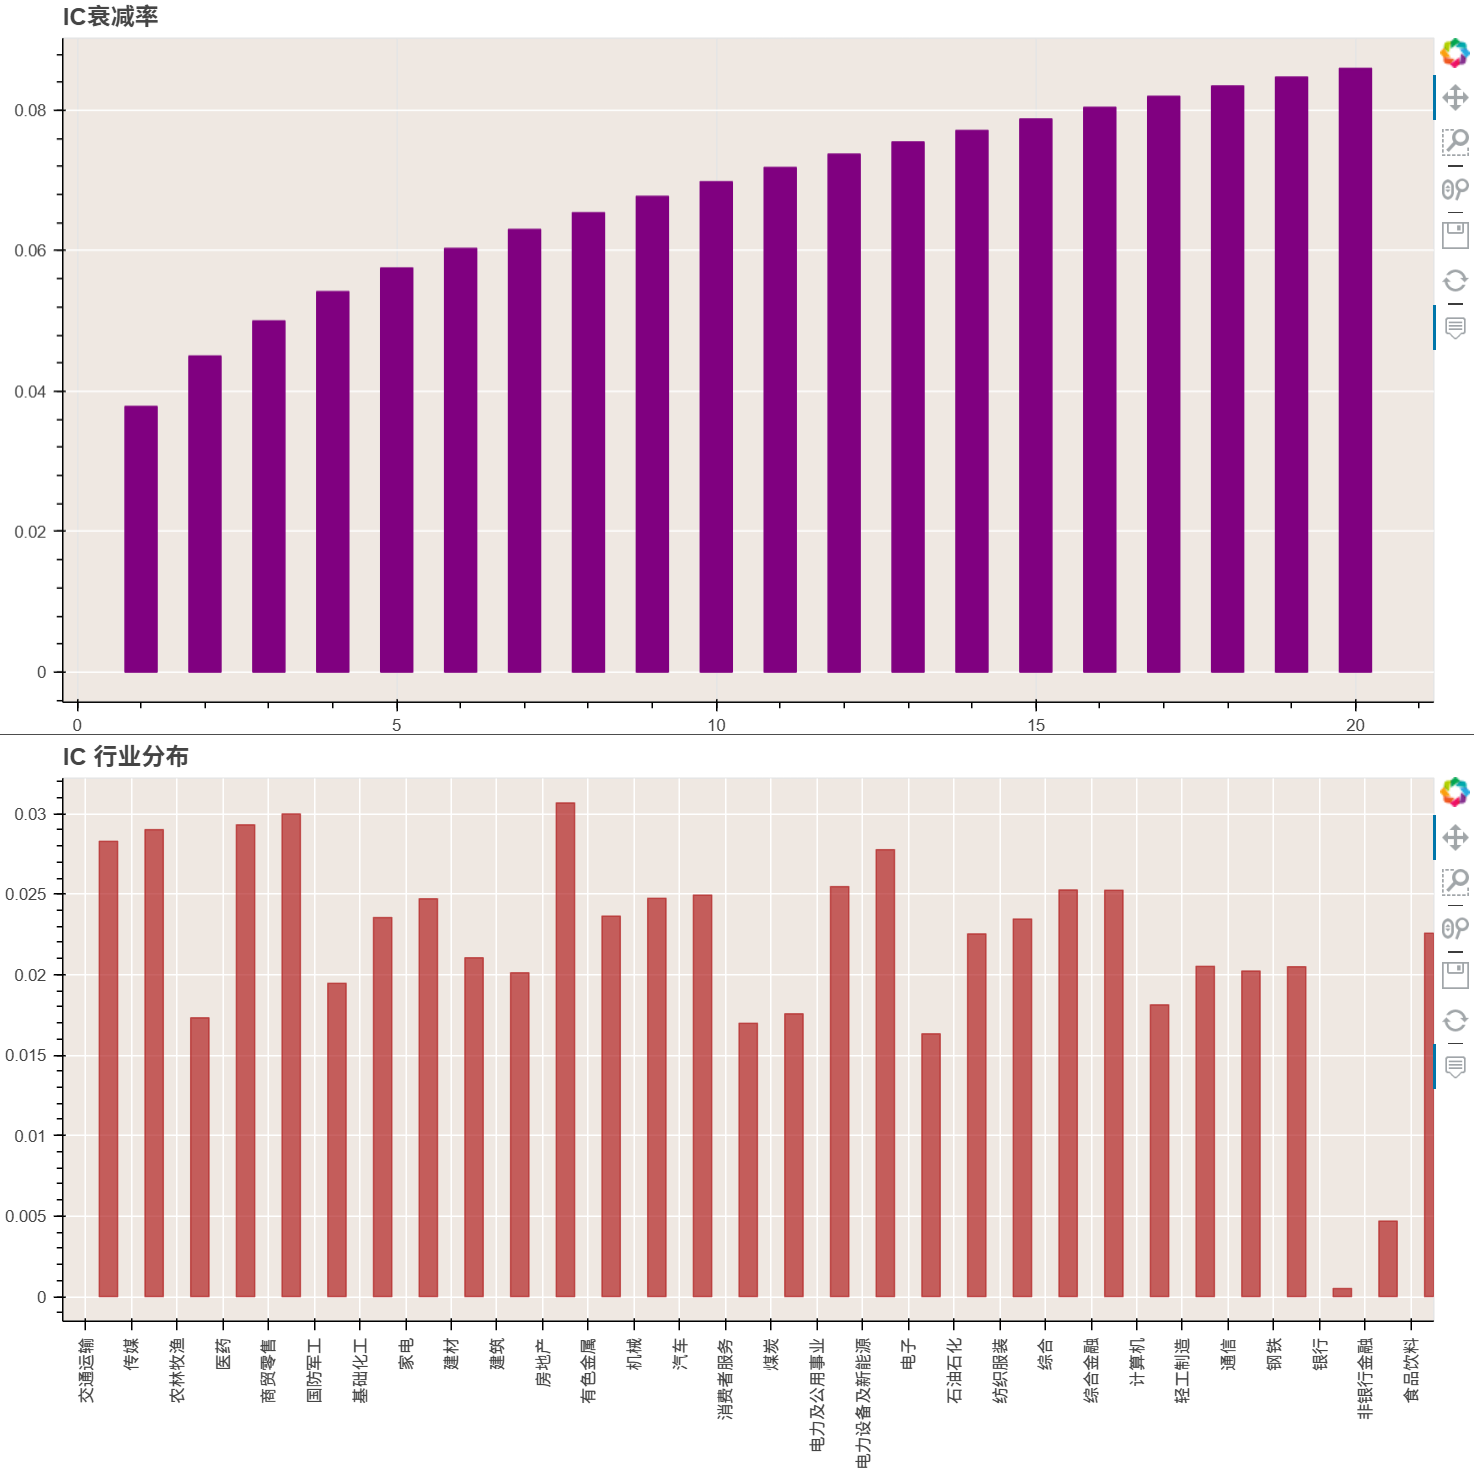

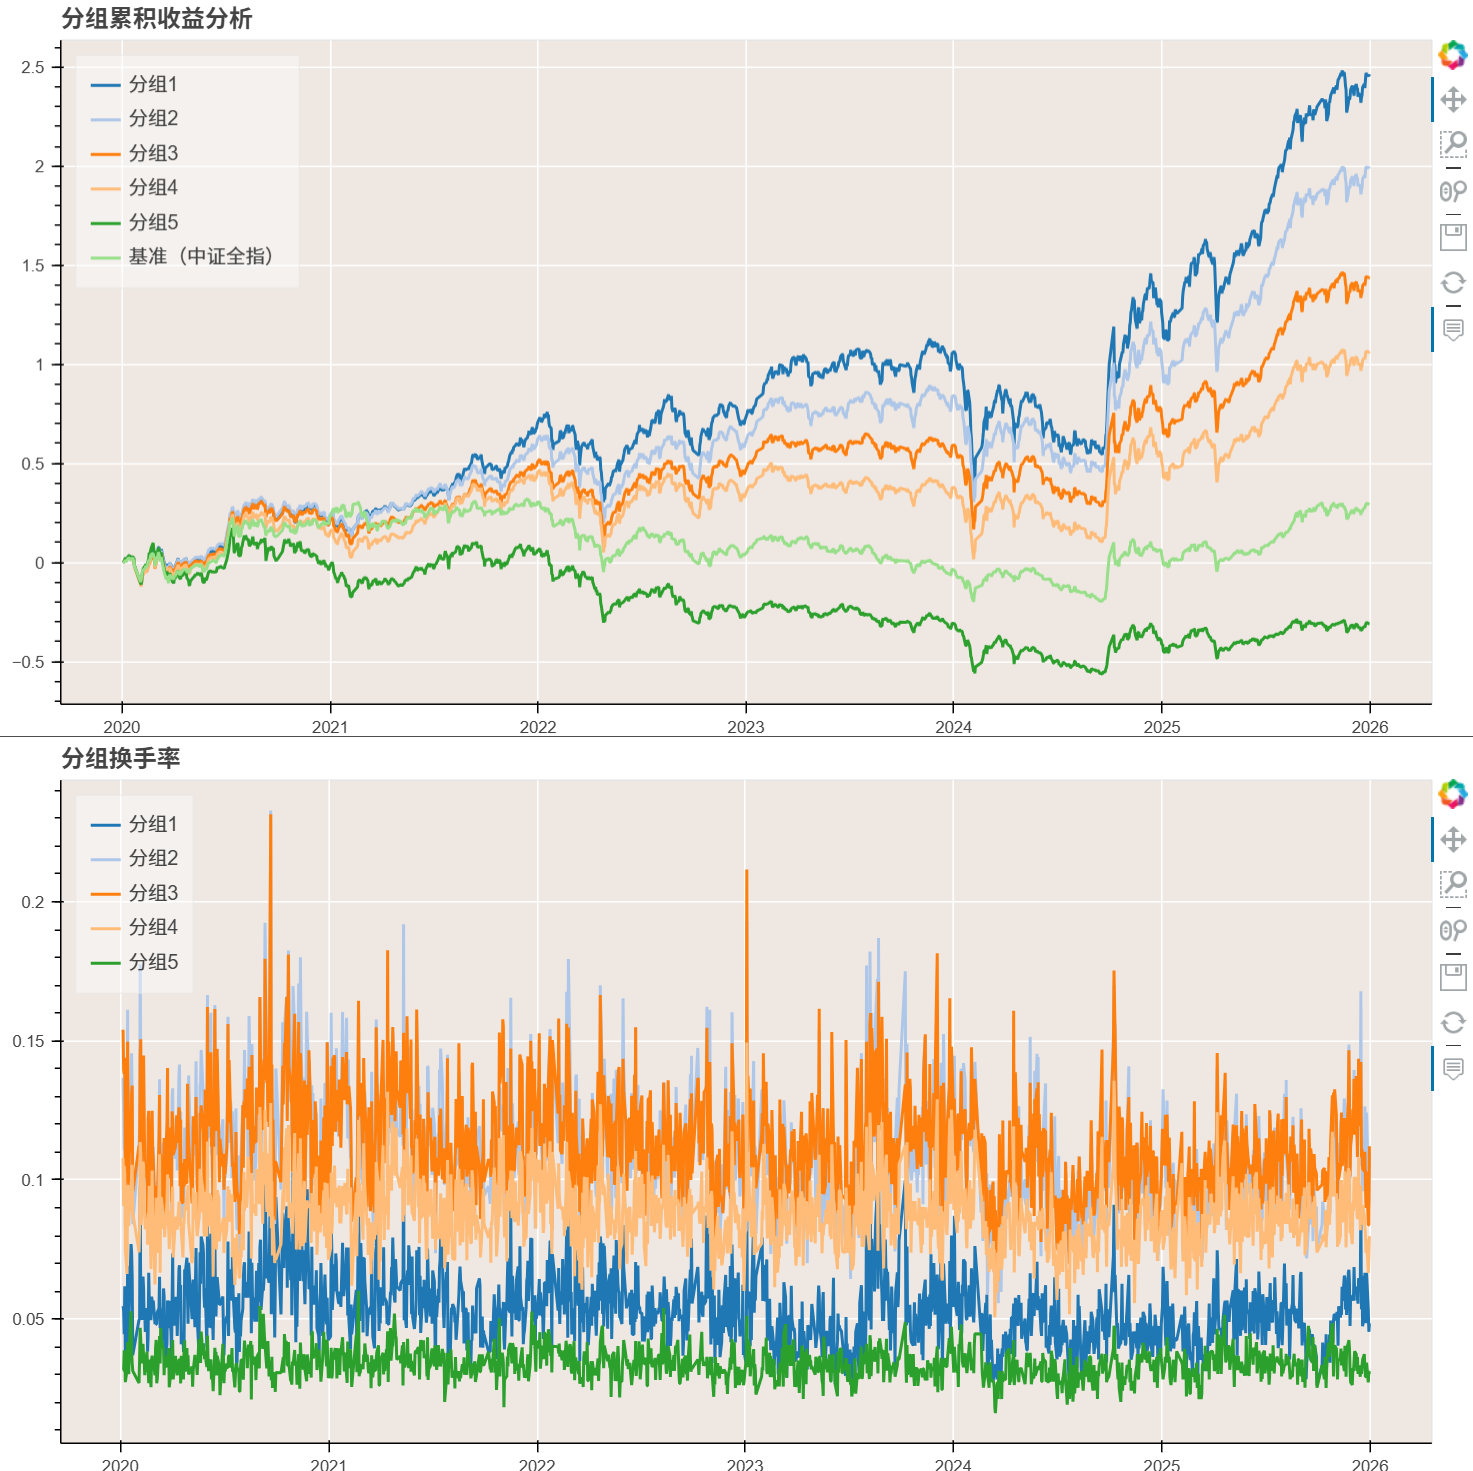

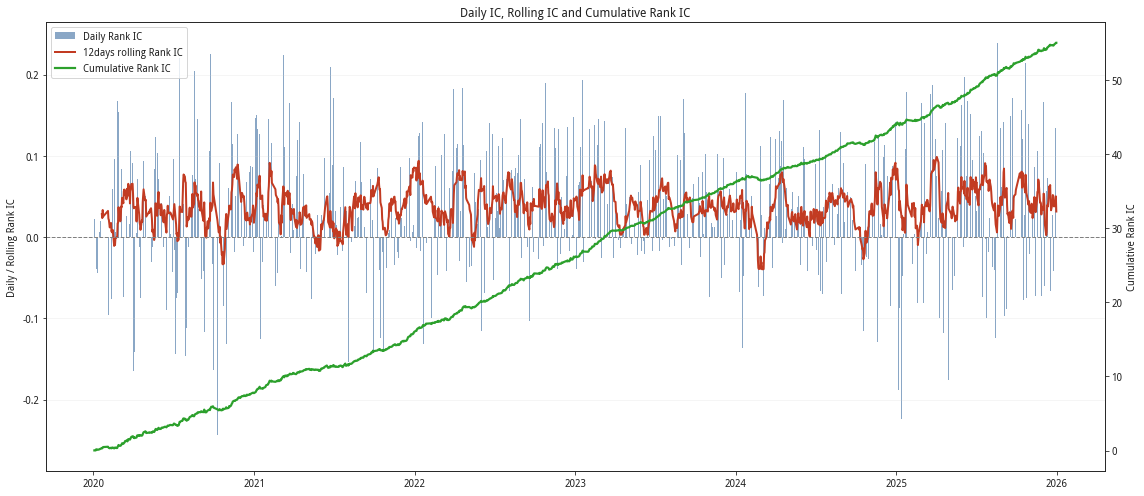

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 替换为你的五年因子测试结果变量
ic = result_turnover_spill.ic.dropna()

rolling_window = 12  # 可改为 12，与米筐默认图保持一致
rolling_ic = ic.rolling(rolling_window).mean()
cum_ic = ic.cumsum()

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "#222222",
    "axes.labelcolor": "#222222",
    "xtick.color": "#222222",
    "ytick.color": "#222222",
    "text.color": "#222222",
    "grid.color": "#D0D0D0",
})

fig, ax1 = plt.subplots(figsize=(16, 7))

# 左轴：每日 IC 柱状图 + 滚动 IC
bars = ax1.bar(
    ic.index,
    ic,
    width=0.8,
    color="#4C78A8",
    alpha=0.65,
    label="Daily Rank IC",
)

line_roll, = ax1.plot(
    rolling_ic.index,
    rolling_ic,
    color="#C23B22",
    linewidth=2,
    label=f"{rolling_window}days rolling Rank IC",
)

ax1.axhline(0, color="gray", linewidth=1, linestyle="--")
ax1.set_ylabel("Daily / Rolling Rank IC")
ax1.set_title("Daily IC, Rolling IC and Cumulative Rank IC")

# 右轴：累计 IC
ax2 = ax1.twinx()

line_cum, = ax2.plot(
    cum_ic.index,
    cum_ic,
    color="#2CA02C",
    linewidth=2.2,
    label="Cumulative Rank IC",
)

ax2.set_ylabel("Cumulative Rank IC")

# 横轴日期格式
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.grid(axis="y", alpha=0.25)

# 合并双轴图例
ax1.legend(
    [bars, line_roll, line_cum],
    ["Daily Rank IC", f"{rolling_window}days rolling Rank IC", "Cumulative Rank IC"],
    loc="upper left",
)

fig.tight_layout()
plt.show()